CSV files available:
['/content/Housing.csv']

First 5 rows:
      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  

Dataset shape:
(545, 13)

Column name

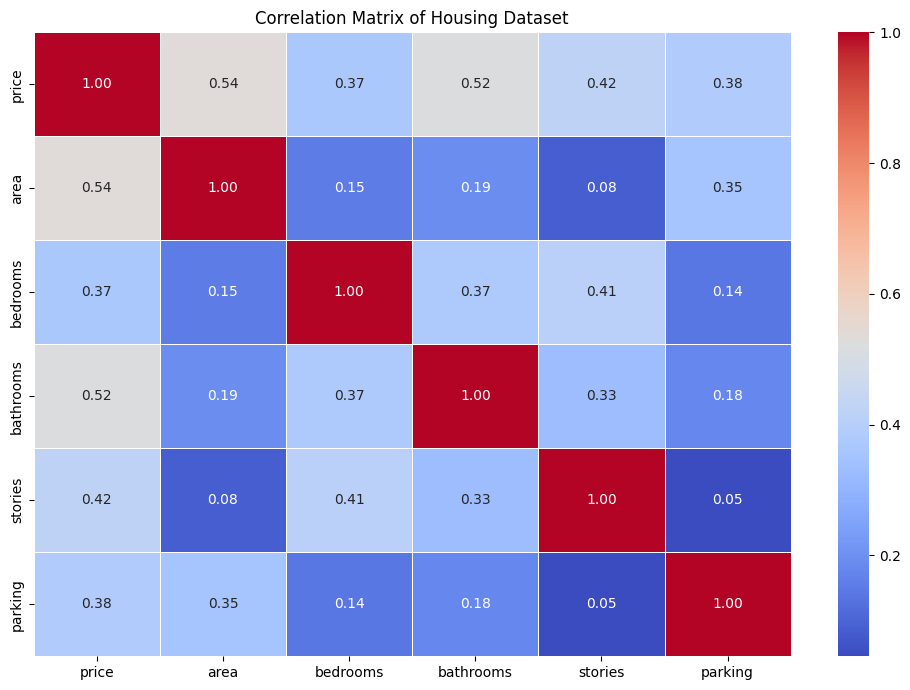


Correlation with House Price:
area         0.535997
bathrooms    0.517545
stories      0.420712
parking      0.384394
bedrooms     0.366494
Name: price, dtype: float64


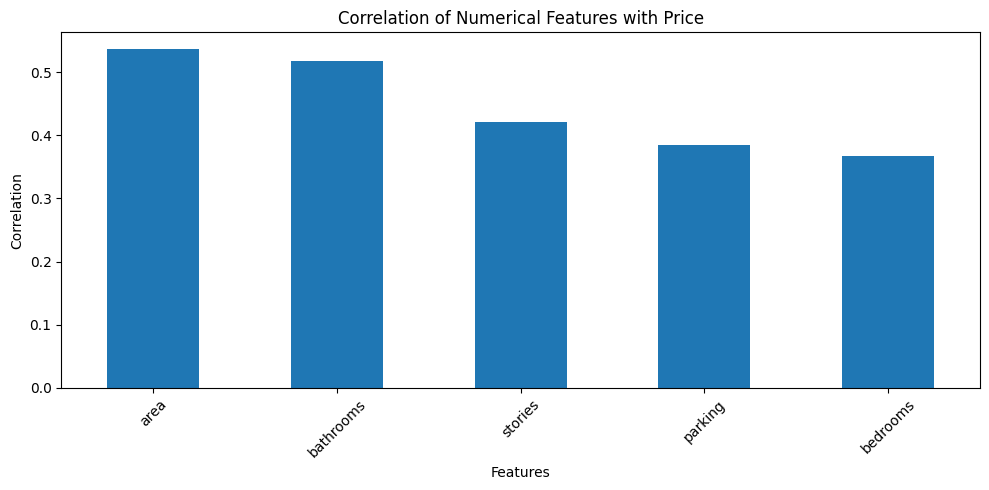


Training samples: 436
Testing samples: 109

Model training completed!

Actual vs Predicted Prices:
   Actual Price  Predicted Price
0       4060000       5164653.90
1       6650000       7224722.30
2       3710000       3109863.24
3       6440000       4612075.33
4       2800000       3294646.26
5       4900000       3532275.10
6       5250000       5611774.57
7       4543000       6368145.99
8       2450000       2722856.96
9       3353000       2629405.62

Regression Coefficients:
                             Feature   Coefficient
                           num__area  2.359688e+02
                       num__bedrooms  7.677870e+04
                      num__bathrooms  1.094445e+06
                        num__stories  4.074766e+05
                        num__parking  2.248419e+05
                    cat__mainroad_no -1.839600e+05
                   cat__mainroad_yes  1.839600e+05
                   cat__guestroom_no -1.158050e+05
                  cat__guestroom_yes  1.158050e+05
 

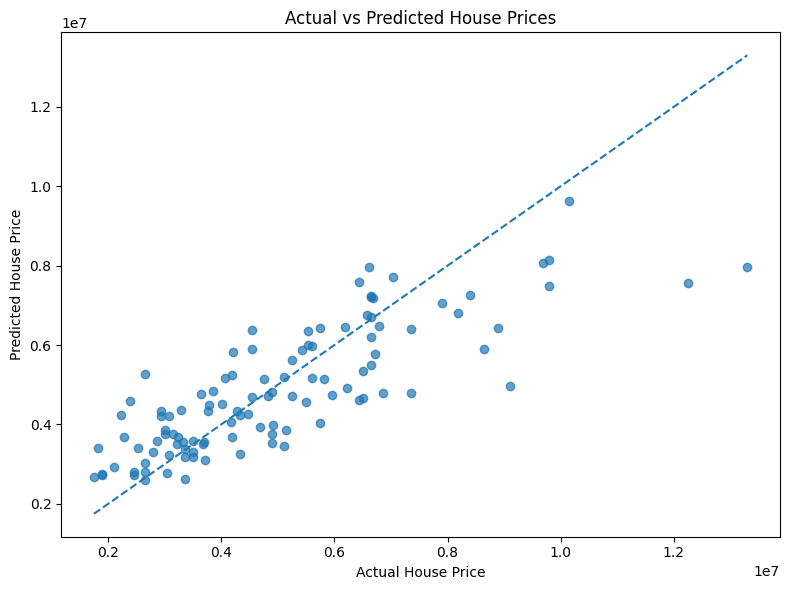


========== RESULT ==========
Multiple Linear Regression was performed successfully.
Correlation analysis was completed.
Coefficients, intercept, and evaluation metrics were calculated.


In [1]:

# MACHINE LEARNING LAB - CO2
# PROGRAM 9: MULTIPLE LINEAR REGRESSION AND CORRELATION
# Dataset: Housing.csv
# Platform: Google Colab

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. LOAD DATASET
# --------------------------------------------------

print("CSV files available:")
print(glob.glob("/content/*.csv"))

file_path = "/content/Housing.csv"

if not os.path.exists(file_path):
    csv_files = glob.glob("/content/*.csv")
    if len(csv_files) == 1:
        file_path = csv_files[0]
    else:
        raise FileNotFoundError(
            "Upload Housing.csv to Colab or update file_path."
        )

df = pd.read_csv(file_path)

# Clean column names
df.columns = df.columns.str.strip()

print("\nFirst 5 rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())


# --------------------------------------------------
# 2. DATA PREPROCESSING
# --------------------------------------------------

target = "price"

if target not in df.columns:
    raise ValueError(
        "Target column 'price' was not found. "
        "Check the printed column names."
    )

# Convert target to numeric and remove invalid target rows
df[target] = pd.to_numeric(df[target], errors="coerce")
df = df.dropna(subset=[target]).copy()

X = df.drop(columns=[target])
y = df[target]

# Separate numerical and categorical features
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("\nNumerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)


# --------------------------------------------------
# 3. CORRELATION ANALYSIS
# --------------------------------------------------

# Correlation applies directly to numerical columns.
numeric_df = df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

print("\nCorrelation Matrix:")
print(correlation_matrix.round(2))

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Matrix of Housing Dataset")
plt.tight_layout()
plt.show()

# Correlation of numerical features with house price
if target in correlation_matrix.columns:
    price_corr = correlation_matrix[target].drop(
        labels=[target]
    ).sort_values(ascending=False)

    print("\nCorrelation with House Price:")
    print(price_corr)

    price_corr.plot(kind="bar", figsize=(10, 5))
    plt.title("Correlation of Numerical Features with Price")
    plt.xlabel("Features")
    plt.ylabel("Correlation")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


# --------------------------------------------------
# 4. SPLIT DATA INTO TRAINING AND TESTING SETS
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# --------------------------------------------------
# 5. HANDLE MISSING VALUES AND CATEGORICAL DATA
# --------------------------------------------------

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])


# --------------------------------------------------
# 6. BUILD MULTIPLE LINEAR REGRESSION MODEL
# --------------------------------------------------

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

print("\nModel training completed!")


# --------------------------------------------------
# 7. PREDICT HOUSE PRICES
# --------------------------------------------------

y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print("\nActual vs Predicted Prices:")
print(results.head(10).round(2))


# --------------------------------------------------
# 8. DISPLAY COEFFICIENTS AND INTERCEPT
# --------------------------------------------------

regressor = model.named_steps["regressor"]

feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": regressor.coef_
})

print("\nRegression Coefficients:")
print(coefficients.to_string(index=False))

print("\nIntercept:")
print(round(regressor.intercept_, 2))


# --------------------------------------------------
# 9. MODEL EVALUATION
# --------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n========== MODEL EVALUATION ==========")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R-squared (R2 Score):", round(r2, 4))


# --------------------------------------------------
# 10. ACTUAL VS PREDICTED PRICE PLOT
# --------------------------------------------------

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.7)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 11. RESULT
# --------------------------------------------------

print("\n========== RESULT ==========")
print("Multiple Linear Regression was performed successfully.")
print("Correlation analysis was completed.")
print("Coefficients, intercept, and evaluation metrics were calculated.")
